# Actividad k-NN: ¿Se puede anticipar el bajo peso al nacer?
**Base:** Registro Estadístico de Nacidos Vivos (ENV) 2025 — INEC Ecuador.

Pregunta: con información de la madre y del embarazo disponible *antes del parto*, ¿puede un clasificador k-NN identificar a los nacidos vivos con **bajo peso al nacer** (< 2.500 g)?

Realizado por: Alexander Fernández Pérez


## 1. Fuente de datos
- **Archivo:** `bases_spss_ENV_EDF/env_spss/ENV_2025.sav` (INEC, Registro Estadístico de Nacidos Vivos 2025).
- **Variable objetivo:** `bajo_peso` = 1 si `peso` < 2.500 g (definición OMS usada en la ficha INEC).

## 2. Fuente de datos

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             ConfusionMatrixDisplay, roc_auc_score)

SEED = 42  # semilla fija para que todo sea reproducible

## 3. Cargar la base
Se leen los códigos numéricos (no las etiquetas) para poder transformarlos.

In [2]:
ruta = Path("bases_spss_ENV_EDF/env_spss/ENV_2025.sav")
env = pd.read_spss(ruta, convert_categoricals=False)
env.shape

(210925, 44)

## 4. Explorar
Primeras filas y tipos de datos.

In [3]:
env.head()

,prov_insc,cant_insc,parr_insc_r,anio_insc,mes_insc,sexo,anio_nac,mes_nac,talla,peso,...,hij_nacm,etnia,est_civil,niv_inst,sabe_leer,prov_res,cant_res,parr_res_r,area_res,residente
0,09,0914,091450,2025.0,10.0,2.0,2017.0,8.0,99.0,99.0,...,0.0,2.0,2.0,9.0,9.0,09,0901,090150,1.0,1.0
1,13,1312,131250,2025.0,3.0,2.0,2025.0,1.0,47.0,2875.0,...,0.0,6.0,2.0,3.0,1.0,08,0803,080358,2.0,2.0
2,13,1310,131050,2025.0,11.0,2.0,2025.0,10.0,47.0,2750.0,...,0.0,6.0,1.0,3.0,1.0,13,1310,131052,2.0,2.0
3,,,,NaN,NaN,2.0,2025.0,5.0,42.0,2000.0,...,0.0,6.0,2.0,3.0,1.0,09,0904,090450,1.0,2.0
4,09,0901,090150,2025.0,3.0,2.0,2025.0,3.0,50.0,3600.0,...,0.0,6.0,2.0,3.0,1.0,09,0901,090150,1.0,1.0


In [9]:
pd.set_option("display.max_columns", None)
env_etiq.head(10)

,prov_insc,cant_insc,parr_insc_r,anio_insc,mes_insc,sexo,anio_nac,mes_nac,talla,peso,sem_gest,tipo_part,apgar1,apgar5,p_emb,lugar_ocur,prov_nac,cant_nac,parr_nac_r,area_nac,asis_por,clampeo,apego,lactancia,nac_mad,cod_pais,anio_mad,mes_mad,edad_mad_r,con_pren,num_emb,num_par,hij_viv,hij_vivm,hij_nacm,etnia,est_civil,niv_inst,sabe_leer,prov_res,cant_res,parr_res_r,area_res,residente
0,Guayas,Pedro Carbo,Pedro Carbo,2025.0,Octubre,Mujer,2017.0,Agosto,Sin información,Sin información,Sin información,Normal,Sin información,Sin información,Simple,Casa,Guayas,Guayaquil,Guayaquil,Urbana,Otro,Sin Información,Sin Información,Sin Información,Ecuatoriana,Ecuador,2007.0,Febrero,<=12,Sin información,1.0,1.0,1.0,0.0,0.0,Afroecuatoriana/Afrodescendiente,Soltera,Sin información,Sin información,Guayas,Guayaquil,Guayaquil,Urbana,Residente
1,Manabí,Rocafuerte,Rocafuerte,2025.0,Marzo,Mujer,2025.0,Enero,47.0,2875.0,37.0,Cesárea,8.0,9.0,Simple,Establecimiento del Ministerio de Salud,Manabí,Sucre,Bahía De Caráquez,Urbana,Médico/a,1.0,1.0,1.0,Ecuatoriana,Ecuador,2014.0,Marzo,<=12,1.0,1.0,1.0,1.0,0.0,0.0,Mestiza,Soltera,Educación Básica,Si,Esmeraldas,Muisne,San José De Chamanga,Rural,No Residente
2,Manabí,Paján,Paján,2025.0,Noviembre,Mujer,2025.0,Octubre,47.0,2750.0,38.0,Cesárea,10.0,10.0,Simple,"Hospital, Clínica o Consultorio Privado",Manabí,Jipijapa,Jipijapa,Urbana,Médico/a,1.0,1.0,1.0,Ecuatoriana,Ecuador,2013.0,Noviembre,<=12,8.0,1.0,1.0,1.0,0.0,0.0,Mestiza,Unida,Educación Básica,Si,Manabí,Paján,Cascol,Rural,No Residente
3,,,,NaN,NaN,Mujer,2025.0,Mayo,42.0,2000.0,37.0,Cesárea,8.0,9.0,Simple,Establecimiento del Ministerio de Salud,Guayas,Guayaquil,Guayaquil,Urbana,Médico/a,1.0,1.0,1.0,Ecuatoriana,Ecuador,2013.0,Agosto,<=12,4.0,1.0,1.0,1.0,0.0,0.0,Mestiza,Soltera,Educación Básica,Si,Guayas,Balzar,Balzar,Urbana,No Residente
4,Guayas,Guayaquil,Guayaquil,2025.0,Marzo,Mujer,2025.0,Marzo,50.0,3600.0,38.0,Normal,8.0,9.0,Simple,"Hospital, Clínica o Consultorio Privado",Guayas,Guayaquil,Guayaquil,Urbana,Médico/a,1.0,1.0,1.0,Ecuatoriana,Ecuador,2013.0,Mayo,<=12,8.0,1.0,1.0,1.0,0.0,0.0,Mestiza,Soltera,Educación Básica,Si,Guayas,Guayaquil,Guayaquil,Urbana,Residente
5,Cañar,La Troncal,La Troncal,2025.0,Marzo,Mujer,2025.0,Marzo,47.0,2140.0,35.0,Normal,7.0,8.0,Simple,Establecimiento del Ministerio de Salud,Guayas,Durán,Eloy Alfaro,Urbana,Médico/a,1.0,2.0,2.0,Ecuatoriana,Ecuador,2013.0,Abril,<=12,0.0,1.0,1.0,1.0,0.0,0.0,Mestiza,Soltera,Educación Básica,Si,Cañar,La Troncal,La Troncal,Urbana,No Residente
6,,,,NaN,NaN,Hombre,2025.0,Noviembre,49.0,3000.0,38.0,Cesárea,8.0,9.0,Simple,Establecimiento del Ministerio de Salud,Esmeraldas,Esmeraldas,Esmeraldas,Urbana,Médico/a,1.0,1.0,1.0,Ecuatoriana,Ecuador,2014.0,Agosto,<=12,1.0,1.0,1.0,1.0,0.0,0.0,Mestiza,Soltera,Educación Básica,Si,Esmeraldas,Quinindé,Cube,Rural,No Residente
7,El Oro,Machala,Machala,2025.0,Octubre,Mujer,2010.0,Abril,50.0,3600.0,39.0,Cesárea,8.0,9.0,Simple,Establecimiento del Ministerio de Salud,El Oro,Machala,Machala,Urbana,Médico/a,1.0,Sin Información,Sin Información,Ecuatoriana,Ecuador,1997.0,Mayo,<=12,5.0,1.0,1.0,1.0,0.0,0.0,Mestiza,Soltera,Educación Básica,Si,El Oro,Machala,Machala,Urbana,Residente
8,,,,NaN,NaN,Mujer,2025.0,Abril,46.0,2800.0,39.0,Cesárea,8.0,9.0,Simple,"Hospital, Clínica o Consultorio Privado",Los Ríos,Vinces,Vinces,Urbana,Médico/a,1.0,1.0,1.0,Ecuatoriana,Ecuador,2012.0,Diciembre,<=12,1.0,1.0,1.0,1.0,0.0,0.0,Montubia,Soltera,Ninguno,No,Los Ríos,Palenque,Palenque,Urbana,No Residente
9,El Oro,Machala,Machala,2025.0,Septiembre,Hombre,2025.0,Septiembre,52.0,3615.0,39.0,Normal,8.0,9.0,Simple,Establecimiento del Ministerio de Salud,El Oro,Machala,Machala,Urbana,Médico/a,1.0,1.0,1.0,Ecuatoriana,Ecuador,2012.0,Diciembre,<=12,4.0,2.0,2.0,2.0,0.0,0.0,Mestiza,Soltera,Educación Básica,Si,El Oro,Machala,Machala,Urbana,Residente


In [4]:
env.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210925 entries, 0 to 210924
Data columns (total 44 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   prov_insc    210925 non-null  object 
 1   cant_insc    210925 non-null  object 
 2   parr_insc_r  210925 non-null  object 
 3   anio_insc    199142 non-null  float64
 4   mes_insc     199142 non-null  float64
 5   sexo         210925 non-null  float64
 6   anio_nac     210925 non-null  float64
 7   mes_nac      210925 non-null  float64
 8   talla        210925 non-null  float64
 9   peso         210925 non-null  float64
 10  sem_gest     210925 non-null  float64
 11  tipo_part    210925 non-null  float64
 12  apgar1       210925 non-null  float64
 13  apgar5       210925 non-null  float64
 14  p_emb        210925 non-null  float64
 15  lugar_ocur   210925 non-null  float64
 16  prov_nac     210925 non-null  object 
 17  cant_nac     210925 non-null  object 
 18  parr_nac_r   210925 non-

Distribución del peso. El código `99` significa *Sin información* (diccionario de variables).

In [10]:
print("Registros con peso = 99:", (env["peso"] == 99).sum())
env.loc[env["peso"] != 99, "peso"].describe()

Registros con peso = 99: 5595


count    205330.000000
mean       3081.204188
std         507.439127
min         500.000000
25%        2800.000000
50%        3100.000000
75%        3400.000000
max        5500.000000
Name: peso, dtype: float64

La base incluye inscripciones tardías de años anteriores. Se trabaja solo con nacimientos ocurridos en 2025.

In [11]:
env["anio_nac"].value_counts().sort_index().tail(5)

anio_nac
2021.0       131
2022.0       170
2023.0       400
2024.0       646
2025.0    208985
Name: count, dtype: int64

## 5. Limpiar y transformar
Decisiones:
1. Mantener solo `anio_nac == 2025` y peso válido.
2. Crear la variable objetivo `bajo_peso`.
3. Usar **solo variables conocidas antes del parto**. Se excluyen `talla`, `apgar`, `tipo_part` y `sem_gest` porque se miden al nacer (y `sem_gest` casi define el resultado; se analiza aparte en la sección 11).
4. Reemplazar códigos `99` por faltantes y eliminar esas filas.
5. Convertir categorías a números que tengan sentido para una distancia (binarias u ordinales), porque k-NN trabaja con distancias.

In [12]:
df = env[(env["anio_nac"] == 2025) & (env["peso"] != 99)].copy()

# Objetivo: 1 = bajo peso al nacer (< 2500 g)
df["bajo_peso"] = (df["peso"] < 2500).astype(int)

# Edad de la madre viene como texto agrupado ("15 - 17", "<=12"...): se pasa a número
edad = df["edad_mad_r"].replace({"<=12": "12", "13 - 14": "13.5", "15 - 17": "16", "99": np.nan}).astype(float)

def sin_99(col):
    return df[col].replace(99, np.nan)

datos = pd.DataFrame({
    "edad_mad":   edad,                              # años
    "con_pren":   sin_99("con_pren"),                # nº de controles prenatales
    "num_emb":    sin_99("num_emb"),                 # nº de embarazos
    "num_par":    sin_99("num_par"),                 # nº de partos
    "hij_vivm":   sin_99("hij_vivm"),                # hijos nacidos vivos que murieron
    "hij_nacm":   sin_99("hij_nacm"),                # hijos nacidos muertos
    # Instrucción ordinal: 0 ninguno, 1 primaria/básica, 2 secundaria/bachillerato, 3 superior, 4 posgrado
    "educ":       df["niv_inst"].map({0: 0, 1: 0, 2: 1, 3: 1, 4: 2, 5: 2, 6: 3, 7: 3, 8: 4}),
    "multiple":   df["p_emb"].map({1: 0, 2: 1, 3: 1, 4: 1}),   # embarazo gemelar o más
    "rural":      (df["area_res"] == 2).astype(int),
    "mujer":      (df["sexo"] == 2).astype(int),
    "indigena":   (df["etnia"] == 1).astype(int),
    "afro":       df["etnia"].isin([2, 3, 4]).astype(int),
    "extranjera": (df["nac_mad"] == 2).astype(int),
    "con_pareja": df["est_civil"].isin([1, 3, 7]).astype(int),  # unida, casada, unión de hecho
    "sem_gest":   sin_99("sem_gest"),                # solo para la comparación de la sección 11
    "bajo_peso":  df["bajo_peso"],
}).dropna()

print("Filas finales:", len(datos))
datos.describe().T[["mean", "min", "max"]].round(2)

Filas finales: 202922


,mean,min,max
edad_mad,26.89,12.0,56.0
con_pren,6.74,0.0,25.0
num_emb,2.18,1.0,37.0
num_par,2.02,1.0,15.0
hij_vivm,0.02,0.0,10.0
hij_nacm,0.02,0.0,6.0
educ,2.09,0.0,4.0
multiple,0.02,0.0,1.0
rural,0.24,0.0,1.0
mujer,0.49,0.0,1.0


In [13]:
# Valores atípicos poco creíbles
datos = datos[datos["num_emb"] <= 20]          # elimina el caso de 37 embarazos
datos["con_pren"] = datos["con_pren"].clip(upper=20)  # tope de 20 controles

Nota: Balance de clases: el bajo peso es poco frecuente (10%). 

In [14]:
datos["bajo_peso"].value_counts(normalize=True).round(3)

bajo_peso
0    0.904
1    0.096
Name: proportion, dtype: float64

## 6. Visualizar
¿Qué variables se asocian con el bajo peso?

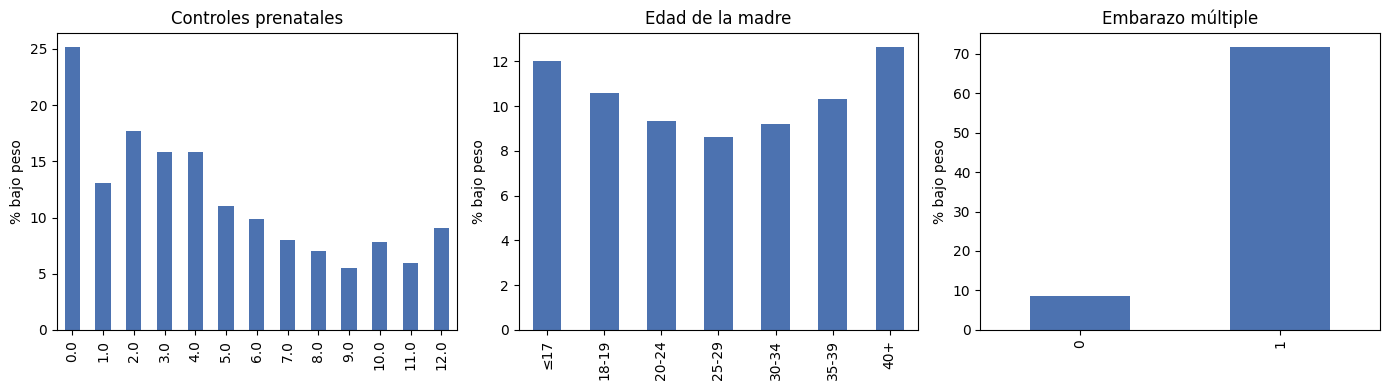

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for eje, var, titulo in zip(ax, ["con_pren", "edad_mad", "multiple"],
                            ["Controles prenatales", "Edad de la madre", "Embarazo múltiple"]):
    grupo = datos[var].clip(upper=12) if var == "con_pren" else datos[var]
    if var == "edad_mad":
        grupo = pd.cut(datos[var], [0, 17, 19, 24, 29, 34, 39, 60],
                       labels=["≤17", "18-19", "20-24", "25-29", "30-34", "35-39", "40+"])
    (datos.groupby(grupo, observed=True)["bajo_peso"].mean() * 100).plot(kind="bar", ax=eje, color="#4C72B0")
    eje.set_title(titulo); eje.set_ylabel("% bajo peso"); eje.set_xlabel("")
plt.tight_layout(); plt.show()

Lectura: el bajo peso baja cuando hay más controles prenatales, es mayor en madres adolescentes y mayores de 40, y es casi la regla en embarazos múltiples.

## 7. Separar entrenamiento y prueba
- k-NN calcula distancias a todos los puntos, así que con 200 mil filas es lento. Se toma una **muestra estratificada de 60.000** registros.
- 80% entrenamiento / 20% prueba, **estratificado** para conservar el 10% de bajo peso en ambos.
- El conjunto de prueba no se usa hasta la evaluación final.

In [20]:
predictores = ["edad_mad", "con_pren", "num_emb", "num_par", "hij_vivm", "hij_nacm", "educ",
               "multiple", "rural", "mujer", "indigena", "afro", "extranjera", "con_pareja"]

muestra = datos.groupby("bajo_peso", group_keys=False).sample(frac=60000 / len(datos), random_state=SEED)

X = muestra[predictores]
y = muestra["bajo_peso"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)
print("% bajo peso en train/test:", round(y_train.mean()*100, 1), "/", round(y_test.mean()*100, 1))

Entrenamiento: (48000, 14)  Prueba: (12000, 14)
% bajo peso en train/test: 9.6 / 9.6


**Desbalance:** k-NN vota por mayoría, así que casi siempre diría "peso normal". Solución simple: **submuestrear la clase mayoritaria solo en entrenamiento** (50/50). La prueba queda intacta, con la proporción real.

In [21]:
pos = y_train[y_train == 1].index
neg = y_train[y_train == 0].sample(n=len(pos), random_state=SEED).index
idx = pos.union(neg)
X_bal, y_bal = X_train.loc[idx], y_train.loc[idx]
y_bal.value_counts()

bajo_peso
1    4623
0    4623
Name: count, dtype: int64

**Escalado:** k-NN usa distancias; sin escalar, `edad_mad` (12–56) pesaría mucho más que `rural` (0–1). Se usa `StandardScaler` dentro de un *pipeline*, así se ajusta solo con datos de entrenamiento.

## 8. Elegir k con validación cruzada
- Validación cruzada estratificada de 5 *folds*, **solo con datos de entrenamiento**.
- Métrica: **balanced accuracy** (promedio del recall de cada clase), adecuada con clases desbalanceadas.
- Se prueban valores impares de k (evitan empates entre dos clases).

In [22]:
valores_k = [1, 3, 5, 9, 15, 25, 41, 61, 81, 101, 151, 201, 301, 401]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

resultados = []
for k in valores_k:
    modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    r = cross_validate(modelo, X_bal, y_bal, cv=cv, scoring="balanced_accuracy", return_train_score=True)
    resultados.append({"k": k,
                       "cv_media": r["test_score"].mean(),
                       "cv_sd": r["test_score"].std(),
                       "train": r["train_score"].mean()})

res = pd.DataFrame(resultados)
res.round(3)

,k,cv_media,cv_sd,train
0,1,0.549,0.013,0.885
1,3,0.567,0.007,0.762
2,5,0.570,0.008,0.717
3,9,0.579,0.010,0.678
4,15,0.581,0.012,0.656
5,25,0.586,0.012,0.643
6,41,0.594,0.010,0.627
7,61,0.596,0.013,0.622
8,81,0.600,0.008,0.617
9,101,0.598,0.011,0.615


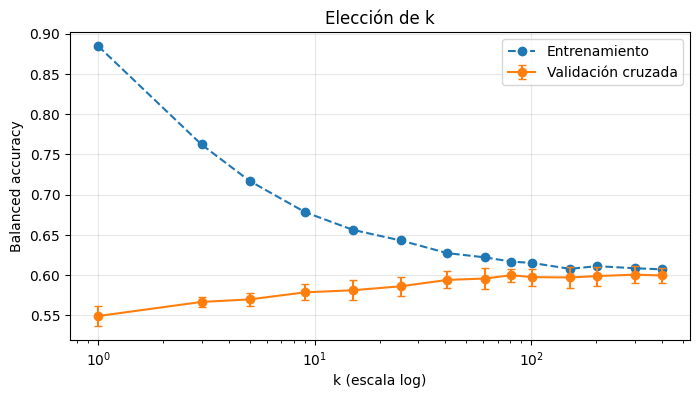

In [23]:
plt.figure(figsize=(8, 4))
plt.plot(res["k"], res["train"], "o--", label="Entrenamiento")
plt.errorbar(res["k"], res["cv_media"], yerr=res["cv_sd"], fmt="o-", capsize=3, label="Validación cruzada")
plt.xscale("log")
plt.xlabel("k (escala log)"); plt.ylabel("Balanced accuracy")
plt.title("Elección de k"); plt.legend(); plt.grid(alpha=.3)
plt.show()

Regla de selección (1 error estándar): la curva se aplana para k grandes, así que no se toma ciegamente el máximo. Se elige el **k más pequeño** cuya media de CV está a menos de un error estándar del mejor. Es un modelo más simple y local con un desempeño estadísticamente equivalente.

In [24]:
mejor = res.loc[res["cv_media"].idxmax()]
error_std = mejor["cv_sd"] / np.sqrt(cv.get_n_splits())
umbral = mejor["cv_media"] - error_std
k_elegido = int(res.loc[res["cv_media"] >= umbral, "k"].min())

print(f"Mejor k por CV: {int(mejor['k'])} (balanced acc = {mejor['cv_media']:.3f})")
print(f"Umbral 1-SE: {umbral:.3f}")
print(f"k elegido: {k_elegido}")

Mejor k por CV: 301 (balanced acc = 0.601)
Umbral 1-SE: 0.596
k elegido: 81


## 9. Entrenar el modelo final y evaluar en prueba
Se entrena con todo el conjunto balanceado y el k elegido. Recién aquí se usa el conjunto de prueba.

In [25]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_elegido))
knn.fit(X_bal, y_bal)

pred = knn.predict(X_test)
prob = knn.predict_proba(X_test)[:, 1]

print(f"Accuracy:          {accuracy_score(y_test, pred):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, pred):.3f}")
print(f"ROC AUC:           {roc_auc_score(y_test, prob):.3f}")
print(f"Referencia: decir siempre 'no' daría accuracy = {1 - y_test.mean():.3f} y balanced accuracy = 0.500")

Accuracy:          0.681
Balanced accuracy: 0.584
ROC AUC:           0.631
Referencia: decir siempre 'no' daría accuracy = 0.904 y balanced accuracy = 0.500


### Reporte de clasificación
- **Precision:** de los que el modelo marca como bajo peso, cuántos lo son.
- **Recall:** de los bebés con bajo peso, cuántos detecta.
- **F1:** media armónica de ambos.

In [16]:
print(classification_report(y_test, pred, target_names=["Peso normal", "Bajo peso"], zero_division=0))

              precision    recall  f1-score   support

 Peso normal       0.92      0.70      0.80     10844
   Bajo peso       0.14      0.46      0.22      1156

    accuracy                           0.68     12000
   macro avg       0.53      0.58      0.51     12000
weighted avg       0.85      0.68      0.74     12000



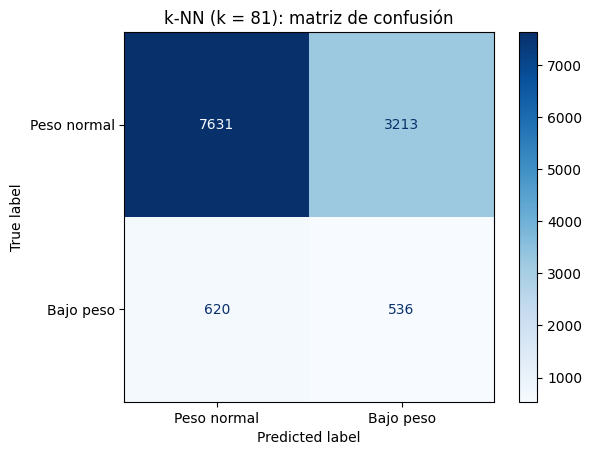

In [26]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Peso normal", "Bajo peso"], cmap="Blues")
plt.title(f"k-NN (k = {k_elegido}): matriz de confusión")
plt.show()

**Lectura:** el modelo detecta casi la mitad de los casos de bajo peso (recall de la clase 1), pero con muchos falsos positivos (precision baja). Es esperable: con solo información prenatal y sociodemográfica, el riesgo es difuso.

## 10. Predecir un caso nuevo
Dos perfiles hipotéticos (no están en entrenamiento ni en prueba).

In [27]:
nuevos = pd.DataFrame([
    # Madre adolescente, 2 controles, primer embarazo, rural, indígena, sin pareja, gemelos
    {"edad_mad": 16, "con_pren": 2, "num_emb": 1, "num_par": 1, "hij_vivm": 0, "hij_nacm": 0, "educ": 1,
     "multiple": 1, "rural": 1, "mujer": 1, "indigena": 1, "afro": 0, "extranjera": 0, "con_pareja": 0},
    # Madre de 29 años, 9 controles, segundo embarazo, urbana, universitaria, con pareja, embarazo simple
    {"edad_mad": 29, "con_pren": 9, "num_emb": 2, "num_par": 2, "hij_vivm": 0, "hij_nacm": 0, "educ": 3,
     "multiple": 0, "rural": 0, "mujer": 0, "indigena": 0, "afro": 0, "extranjera": 0, "con_pareja": 1},
], index=["Perfil A (riesgo alto)", "Perfil B (riesgo bajo)"])

salida = pd.DataFrame({
    "predicción": np.where(knn.predict(nuevos) == 1, "Bajo peso", "Peso normal"),
    "prob. bajo peso": knn.predict_proba(nuevos)[:, 1].round(2),
}, index=nuevos.index)
salida

,predicción,prob. bajo peso
Perfil A (riesgo alto),Bajo peso,0.63
Perfil B (riesgo bajo),Peso normal,0.31


## 11. Comparaciones
### a) Random forest (mismos datos y variables)

In [28]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=SEED, n_jobs=-1)
rf.fit(X_bal, y_bal)
pred_rf = rf.predict(X_test)

comparacion = pd.DataFrame({
    "k-NN": [balanced_accuracy_score(y_test, pred), roc_auc_score(y_test, prob)],
    "Random forest": [balanced_accuracy_score(y_test, pred_rf), roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])],
}, index=["Balanced accuracy", "ROC AUC"]).round(3)
comparacion

,k-NN,Random forest
Balanced accuracy,0.584,0.609
ROC AUC,0.631,0.657


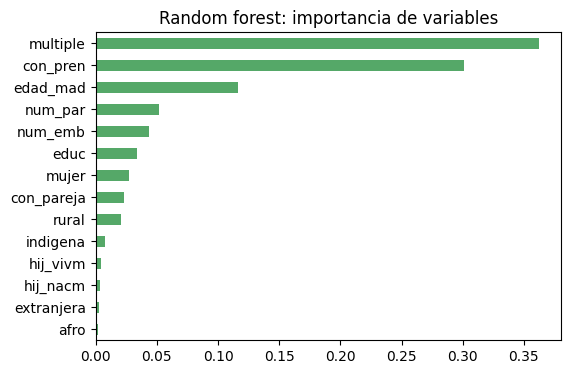

In [29]:
pd.Series(rf.feature_importances_, index=predictores).sort_values().plot(kind="barh", figsize=(6, 4), color="#55A868")
plt.title("Random forest: importancia de variables"); plt.show()

### b) ¿Qué pasa si agregamos las semanas de gestación?
Se repite la evaluación con `sem_gest` (dato que solo se conoce con certeza al parto). Se usa el mismo k para comparar.

In [30]:
cols_sg = predictores + ["sem_gest"]
X_train_sg = muestra.loc[X_bal.index, cols_sg]
X_test_sg = muestra.loc[X_test.index, cols_sg]

knn_sg = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_elegido)).fit(X_train_sg, y_bal)
pred_sg = knn_sg.predict(X_test_sg)
print(f"Balanced accuracy con sem_gest: {balanced_accuracy_score(y_test, pred_sg):.3f}")
print(f"ROC AUC con sem_gest:           {roc_auc_score(y_test, knn_sg.predict_proba(X_test_sg)[:, 1]):.3f}")
print(classification_report(y_test, pred_sg, target_names=["Peso normal", "Bajo peso"], zero_division=0))

Balanced accuracy con sem_gest: 0.745
ROC AUC con sem_gest:           0.836
              precision    recall  f1-score   support

 Peso normal       0.95      0.91      0.93     10844
   Bajo peso       0.40      0.58      0.48      1156

    accuracy                           0.88     12000
   macro avg       0.68      0.75      0.70     12000
weighted avg       0.90      0.88      0.89     12000



El desempeño sube mucho: la prematurez es el principal determinante inmediato del bajo peso. Pero ese modelo ya no sirve para anticipar el riesgo durante el embarazo